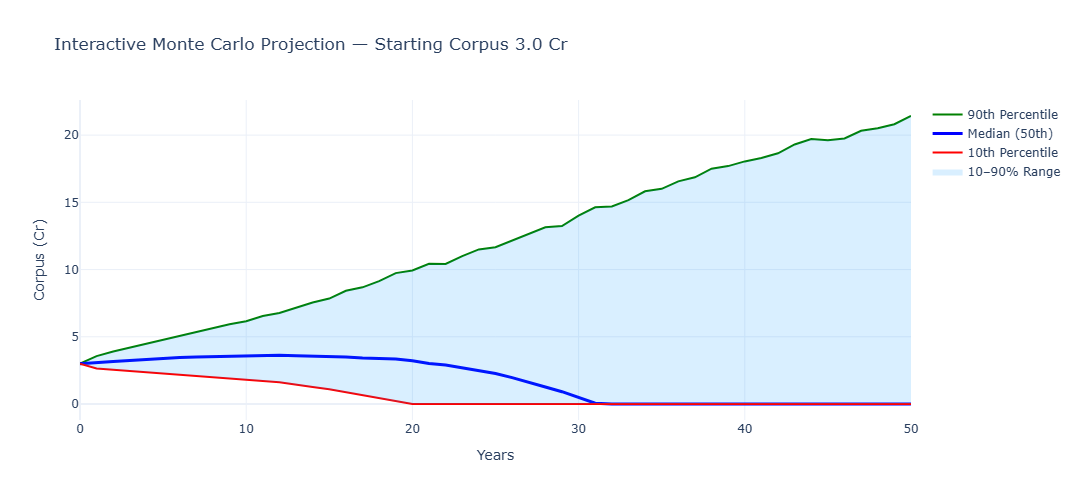


RETIREMENT TABLE — MEDIAN OUTCOME (Corpus 3.0 Cr)
Year   Start Corpus (Cr)    After Returns (Cr)   Planned Wd (L)     Actual Wd (L)      End Corpus (Cr)      Status
------------------------------------------------------------------------------------------------------------------------
0      3.00                 3.00                 0.00               0.00               3.00                 (start of retirement)
1      3.00                 3.21                 12.00              12.00              3.11                 
2      3.11                 3.32                 12.60              12.60              3.16                 
3      3.16                 3.38                 13.22              13.22              3.24                 
4      3.24                 3.46                 13.90              13.90              3.33                 
25     2.47                 2.65                 36.90              36.90              2.26                 
29     1.27                 1.36      

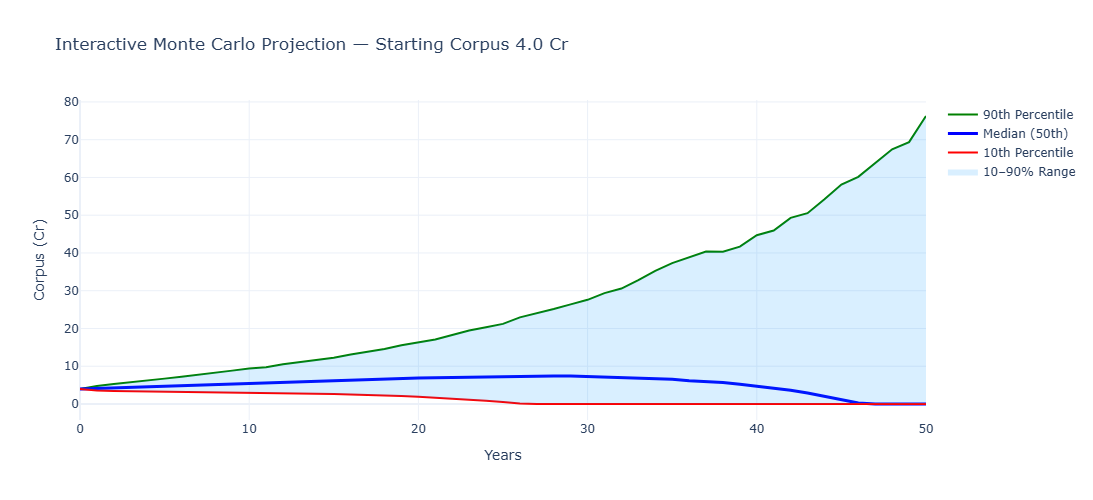


RETIREMENT TABLE — MEDIAN OUTCOME (Corpus 4.0 Cr)
Year   Start Corpus (Cr)    After Returns (Cr)   Planned Wd (L)     Actual Wd (L)      End Corpus (Cr)      Status
------------------------------------------------------------------------------------------------------------------------
0      4.00                 4.00                 0.00               0.00               4.00                 (start of retirement)
1      4.00                 4.28                 12.00              12.00              4.15                 
2      4.15                 4.44                 12.61              12.61              4.31                 
3      4.31                 4.61                 13.23              13.23              4.45                 
4      4.45                 4.76                 13.89              13.89              4.60                 
25     7.13                 7.63                 38.11              38.11              7.33                 
44     2.90                 3.11      

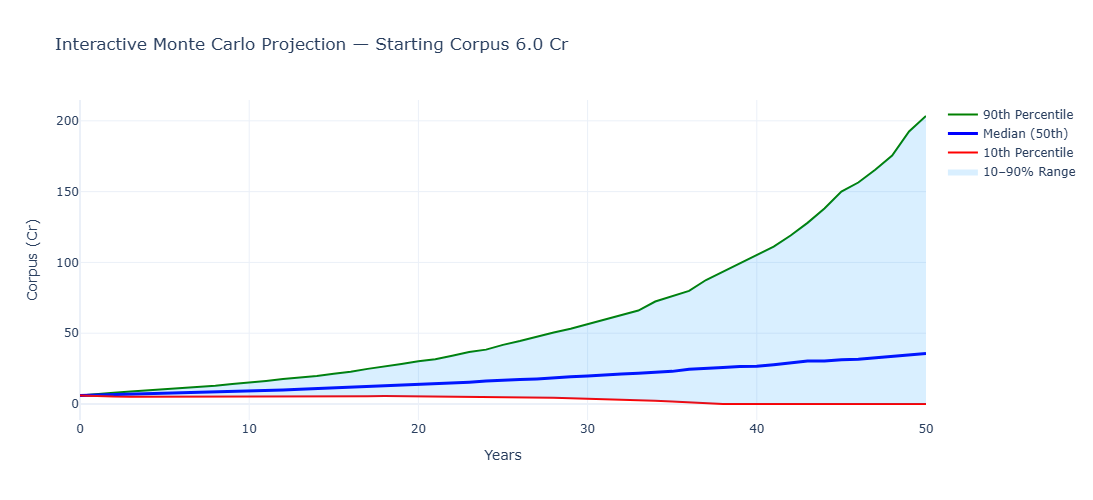


RETIREMENT TABLE — MEDIAN OUTCOME (Corpus 6.0 Cr)
Year   Start Corpus (Cr)    After Returns (Cr)   Planned Wd (L)     Actual Wd (L)      End Corpus (Cr)      Status
------------------------------------------------------------------------------------------------------------------------
0      6.00                 6.00                 0.00               0.00               6.00                 (start of retirement)
1      6.00                 6.42                 12.00              12.00              6.30                 
2      6.30                 6.74                 12.61              12.61              6.56                 
3      6.56                 7.02                 13.24              13.24              6.82                 
4      6.82                 7.30                 13.89              13.89              7.06                 
25     16.18                17.32                38.33              38.33              16.49                
46     31.30                33.49     

In [21]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# -------------------------------------------------------------
# WHERE TO ADJUST PARAMETERS
# -------------------------------------------------------------

corpus_list = [3e7, 4e7, 6e7]     # Starting corpuses: 3 Cr, 4 Cr, 6 Cr
withdrawal_start = 12e5          # 12 lakh per year (inflation-adjusted)
years = 50                       # Retirement duration
n_sims = 2000                    # Number of Monte Carlo simulations

# Inflation assumptions
infl_mean = 0.05                 # 5% average inflation
infl_sd   = 0.02                 # 2% standard deviation

# Portfolio return assumptions
ret_mean = 0.07                  # 7% average return
ret_sd   = 0.12                  # 12% standard deviation


# -------------------------------------------------------------
# MONTE CARLO SIMULATION
# -------------------------------------------------------------

def monte_carlo(corpus_start, withdrawal_start, years, n_sims,
                ret_mean, ret_sd, infl_mean, infl_sd):

    corpus_paths = np.zeros((n_sims, years + 1))
    withdrawal_paths = np.zeros((n_sims, years + 1))
    exhaustion_years = np.full(n_sims, None)

    for sim in range(n_sims):
        corpus = corpus_start
        withdrawal = withdrawal_start

        corpus_paths[sim, 0] = corpus
        withdrawal_paths[sim, 0] = 0

        for yr in range(1, years + 1):

            if corpus <= 0:
                corpus_paths[sim, yr] = 0
                withdrawal_paths[sim, yr] = 0
                if exhaustion_years[sim] is None:
                    exhaustion_years[sim] = yr
                continue

            # Random return & inflation
            r = np.random.normal(ret_mean, ret_sd)
            inf = np.random.normal(infl_mean, infl_sd)

            # Apply return
            corpus *= (1 + r)

            # Withdrawal
            corpus -= withdrawal
            corpus = max(corpus, 0)

            corpus_paths[sim, yr] = corpus
            withdrawal_paths[sim, yr] = withdrawal

            # Next year's withdrawal
            withdrawal *= (1 + inf)

    return corpus_paths, withdrawal_paths, exhaustion_years


# -------------------------------------------------------------
# RUN SIMULATIONS
# -------------------------------------------------------------

results = {}

for corpus in corpus_list:
    paths, wds, exhaust = monte_carlo(
        corpus, withdrawal_start, years, n_sims,
        ret_mean, ret_sd, infl_mean, infl_sd
    )
    results[corpus] = {"paths": paths, "withdrawals": wds, "exhaust": exhaust}


# -------------------------------------------------------------
# INTERACTIVE PLOTLY CHART (Median, 10th, 90th)
# -------------------------------------------------------------

def plot_interactive_chart(paths, years, corpus_label):

    p10 = np.percentile(paths, 10, axis=0) / 1e7
    p50 = np.percentile(paths, 50, axis=0) / 1e7
    p90 = np.percentile(paths, 90, axis=0) / 1e7

    x = list(range(years + 1))

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=x, y=p90, mode='lines', name='90th Percentile',
        line=dict(color='green', width=2),
        hovertemplate='Year %{x}<br>Corpus %{y:.2f} Cr'
    ))

    fig.add_trace(go.Scatter(
        x=x, y=p50, mode='lines', name='Median (50th)',
        line=dict(color='blue', width=3),
        hovertemplate='Year %{x}<br>Corpus %{y:.2f} Cr'
    ))

    fig.add_trace(go.Scatter(
        x=x, y=p10, mode='lines', name='10th Percentile',
        line=dict(color='red', width=2),
        hovertemplate='Year %{x}<br>Corpus %{y:.2f} Cr'
    ))

    # Fill between 10th and 90th
    fig.add_trace(go.Scatter(
        x=x + x[::-1],
        y=list(p90) + list(p10[::-1]),
        fill='toself',
        fillcolor='rgba(0, 150, 255, 0.15)',
        line=dict(color='rgba(255,255,255,0)'),
        hoverinfo='skip',
        name='10–90% Range'
    ))

    fig.update_layout(
        title=f"Interactive Monte Carlo Projection — Starting Corpus {corpus_label} Cr",
        xaxis_title="Years",
        yaxis_title="Corpus (Cr)",
        hovermode="x unified",
        template="plotly_white",
        width=900,
        height=500
    )

    fig.show()


# -------------------------------------------------------------
# TABLE FOR MEDIAN PATH (your exact format)
# -------------------------------------------------------------

def print_median_table(corpus_start, paths, withdrawals, ret_mean, corpus_label):

    median_corpus = np.percentile(paths, 50, axis=0)
    median_wd = np.percentile(withdrawals, 50, axis=0)

    print("\n" + "="*120)
    print(f"RETIREMENT TABLE — MEDIAN OUTCOME (Corpus {corpus_label} Cr)")
    print("="*120)

    # Find exhaustion year
    exhaustion_year = None
    for yr in range(1, len(median_corpus)):
        if median_corpus[yr] == 0 and median_corpus[yr-1] > 0:
            exhaustion_year = yr
            break

    # Rows to show
    rows = list(range(0, 5))              # first 5 years
    rows.append(len(median_corpus)//2)    # middle year

    if exhaustion_year:
        rows.extend(range(max(0, exhaustion_year-3), exhaustion_year+1))
    else:
        rows.extend(range(len(median_corpus)-5, len(median_corpus)))

    rows = sorted(set(rows))

    # Header
    print(f"{'Year':<6} {'Start Corpus (Cr)':<20} {'After Returns (Cr)':<20} "
          f"{'Planned Wd (L)':<18} {'Actual Wd (L)':<18} {'End Corpus (Cr)':<20} {'Status'}")
    print("-"*120)

    for yr in rows:
        if yr == 0:
            start_c = corpus_start / 1e7
            after_ret = start_c
            planned = 0
            actual = 0
            end_c = start_c
            status = "(start of retirement)"
        else:
            start_c = median_corpus[yr-1] / 1e7
            after_ret = start_c * (1 + ret_mean)
            planned = median_wd[yr] / 1e5
            actual = min(planned, after_ret * 1e7 / 1e5)
            end_c = median_corpus[yr] / 1e7

            if exhaustion_year and yr == exhaustion_year:
                status = "→ EXHAUSTED"
            elif exhaustion_year and yr > exhaustion_year:
                status = "(exhausted)"
            else:
                status = ""

        print(f"{yr:<6} {start_c:<20.2f} {after_ret:<20.2f} "
              f"{planned:<18.2f} {actual:<18.2f} {end_c:<20.2f} {status}")


# -------------------------------------------------------------
# RUN OUTPUTS
# -------------------------------------------------------------

for corpus in corpus_list:
    paths = results[corpus]["paths"]
    wds = results[corpus]["withdrawals"]

    # Interactive chart
    plot_interactive_chart(paths, years, corpus_label=corpus/1e7)

    # Table
    print_median_table(
        corpus_start=corpus,
        paths=paths,
        withdrawals=wds,
        ret_mean=ret_mean,
        corpus_label=corpus/1e7
    )
